In [51]:
##Importando bibliotecas
import yfinance as yf
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import matplotlib
from datetime import date
matplotlib.rcParams['figure.figsize'] = (18,8)

In [52]:
""" ativos = "ITUB4.SA VIIA3.SA"

carteira = yf.download(ativos, period="5y")['Adj Close']
carteira """

' ativos = "ITUB4.SA VIIA3.SA"\n\ncarteira = yf.download(ativos, period="5y")[\'Adj Close\']\ncarteira '

In [53]:
""" dados = {'2019-06-17' [('ITUB4', 'c', 500)],
         '2021-02-10' [('VIIA3', 'c', 1000)],
         '2021-09-13' [('ITUB4', 'v', 300)]
         } """
arquivo = pd.read_excel(r'carteira_giuvan.xlsx', sheet_name='corretora')
arquivo.index = arquivo["Data"] 
arquivo


,Data,ticker,C/V,Quantidade
Data,,,,
2019-06-17,2019-06-17,ITUB4,C,500
2021-02-10,2021-02-10,VIIA3,C,1000
2021-09-13,2021-09-13,ITUB4,V,300
2019-08-26,2019-08-26,MGLU3,C,100
2022-03-06,2022-03-06,PETR4,C,200
2021-03-10,2021-03-10,VIIA3,C,100
2021-01-28,2021-01-28,BRFS3,C,5
2021-08-03,2021-08-03,JBSS3,C,200
2021-04-16,2021-04-16,VIIA3,V,100


In [54]:
arquivo.columns = ['Data', 'ticker', 'C/V', 'Quantidade']
arquivo.drop(columns='Data', inplace=True)
arquivo

,ticker,C/V,Quantidade
Data,,,
2019-06-17,ITUB4,C,500
2021-02-10,VIIA3,C,1000
2021-09-13,ITUB4,V,300
2019-08-26,MGLU3,C,100
2022-03-06,PETR4,C,200
2021-03-10,VIIA3,C,100
2021-01-28,BRFS3,C,5
2021-08-03,JBSS3,C,200
2021-04-16,VIIA3,V,100


In [55]:
trade = pd.pivot_table(arquivo, values='Quantidade', index='Data', columns='ticker', aggfunc=np.sum, fill_value=0)
trade

ticker,BRFS3,CSNA3,ITUB4,JBSS3,MGLU3,MRFG3,PETR4,USIM5,VALE3,VIIA3
Data,,,,,,,,,,
2019-06-17,0,0,500,0,0,0,0,0,0,0
2019-08-26,0,0,0,0,100,0,0,0,0,0
2019-11-10,0,0,0,0,0,0,0,100,0,0
2019-12-16,0,0,0,0,0,0,0,0,0,60
2020-02-15,0,0,100,0,0,0,0,0,0,0
2020-04-02,0,100,0,0,0,0,0,0,0,0
2020-04-08,0,0,0,0,0,60,0,0,0,0
2020-08-30,0,100,0,0,0,0,0,0,0,0
2020-10-11,0,0,0,0,0,0,200,0,0,0


In [56]:
preco = yf.download(tickers=(trade.columns+'.SA').to_list(), start=trade.index[0], rounding=True)['Adj Close']
preco

[*********************100%***********************]  10 of 10 completed


,BRFS3.SA,CSNA3.SA,ITUB4.SA,JBSS3.SA,MGLU3.SA,MRFG3.SA,PETR4.SA,USIM5.SA,VALE3.SA,VIIA3.SA
Date,,,,,,,,,,
2019-06-17,28.70,14.99,31.12,17.64,6.3083,5.29,14.31,7.46,36.53,5.07
2019-06-18,28.20,15.47,31.93,17.39,6.3266,5.20,14.49,7.61,37.84,5.07
2019-06-19,28.60,15.20,32.44,17.95,6.3843,5.13,14.52,7.51,38.06,5.06
2019-06-21,28.66,15.11,33.17,18.64,6.4649,5.15,14.92,7.53,38.16,5.10
2019-06-24,28.89,15.05,33.10,18.41,6.3837,5.21,14.91,7.58,38.13,5.11
...,...,...,...,...,...,...,...,...,...,...
2022-08-10,17.16,15.73,26.38,30.55,3.2900,12.95,30.22,9.11,66.60,2.96
2022-08-11,14.99,16.19,26.42,31.24,3.0400,13.65,29.52,9.35,68.92,2.79
2022-08-12,15.59,16.69,26.74,30.42,3.5800,14.30,31.71,9.51,69.80,3.18


In [57]:
#arquivo.iloc[:,1]
arquivo
arquivo.loc[:,"Quantidade"]

Data
2019-06-17     500
2021-02-10    1000
2021-09-13     300
2019-08-26     100
2022-03-06     200
2021-03-10     100
2021-01-28       5
2021-08-03     200
2021-04-16     100
2020-10-11     200
2020-08-30     100
2020-02-15     100
2019-11-10     100
2021-02-05     155
2020-04-08      60
2019-12-16      60
2022-01-04      25
2020-04-02     100
2022-08-01     100
Name: Quantidade, dtype: int64

In [58]:
#for ticker in trade.columns:
for i, data in enumerate(arquivo.index):
    c_v = arquivo.iloc[i,1]
    if c_v == 'V':
    #arquivo.loc[:,"Quantidade"] = arquivo.iloc[i,2]*(-1)
        #print(c_v)
        arquivo.iloc[i,2] =arquivo.iloc[i,2]*-1

""" for i, data in enumerate(arquivo.index):
    print(i); print(data) """
display(arquivo.loc[:,"Quantidade"])

Data
2019-06-17     500
2021-02-10    1000
2021-09-13    -300
2019-08-26     100
2022-03-06     200
2021-03-10     100
2021-01-28       5
2021-08-03     200
2021-04-16    -100
2020-10-11    -200
2020-08-30     100
2020-02-15     100
2019-11-10     100
2021-02-05     155
2020-04-08     -60
2019-12-16      60
2022-01-04     -25
2020-04-02    -100
2022-08-01    -100
Name: Quantidade, dtype: int64

In [59]:
preco.columns  = preco.columns.str.rstrip('.SA')
preco.dropna(how='all', inplace=True)
trade = trade.reindex(index=preco.index)
trade.fillna(value=0, inplace=True)

In [60]:
posicao = trade.cumsum()
posicao

ticker,BRFS3,CSNA3,ITUB4,JBSS3,MGLU3,MRFG3,PETR4,USIM5,VALE3,VIIA3
Date,,,,,,,,,,
2019-06-17,0.0,0.0,500.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-06-18,0.0,0.0,500.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-06-19,0.0,0.0,500.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-06-21,0.0,0.0,500.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-06-24,0.0,0.0,500.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
2022-08-10,5.0,100.0,800.0,200.0,100.0,60.0,0.0,0.0,255.0,1285.0
2022-08-11,5.0,100.0,800.0,200.0,100.0,60.0,0.0,0.0,255.0,1285.0
2022-08-12,5.0,100.0,800.0,200.0,100.0,60.0,0.0,0.0,255.0,1285.0


In [61]:
aportes = (trade * preco).sum(axis=1)
aportes

Date
2019-06-17    15560.0
2019-06-18        0.0
2019-06-19        0.0
2019-06-21        0.0
2019-06-24        0.0
               ...   
2022-08-10        0.0
2022-08-11        0.0
2022-08-12        0.0
2022-08-15        0.0
2022-08-16        0.0
Length: 787, dtype: float64

<AxesSubplot:xlabel='Date'>

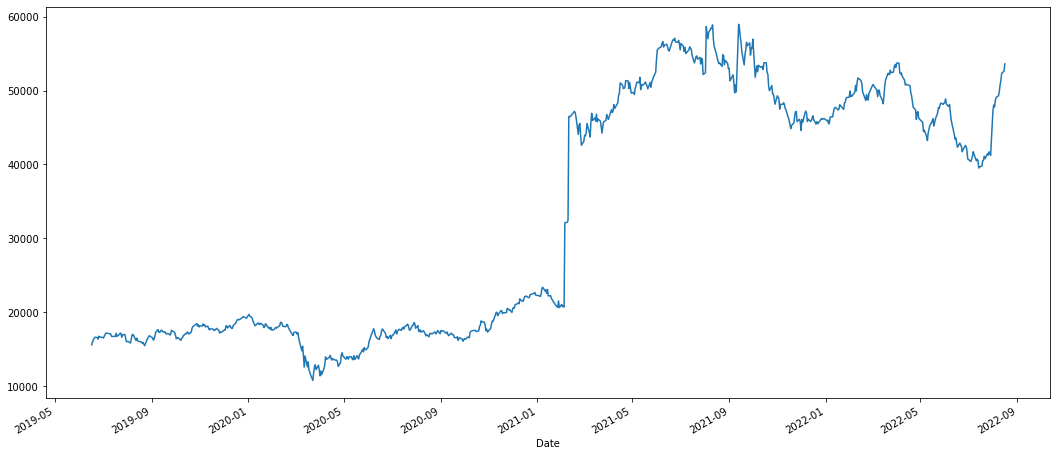

In [62]:
### Consolida saldo
carteira = posicao * preco
carteira['saldo'] = carteira.sum(axis=1)
#carteira = carteira[:-2]
carteira['saldo'].plot(figsize=(18,8))


In [63]:
carteira

ticker,BRFS3,CSNA3,ITUB4,JBSS3,MGLU3,MRFG3,PETR4,USIM5,VALE3,VIIA3,saldo
Date,,,,,,,,,,,
2019-06-17,0.00,0.0,15560.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,15560.00
2019-06-18,0.00,0.0,15965.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,15965.00
2019-06-19,0.00,0.0,16220.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,16220.00
2019-06-21,0.00,0.0,16585.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,16585.00
2019-06-24,0.00,0.0,16550.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,16550.00
...,...,...,...,...,...,...,...,...,...,...,...
2022-08-10,85.80,1573.0,21104.0,6110.0,329.0,777.0,0.0,0.0,16983.0,3803.60,50765.40
2022-08-11,74.95,1619.0,21136.0,6248.0,304.0,819.0,0.0,0.0,17574.6,3585.15,51360.70
2022-08-12,77.95,1669.0,21392.0,6084.0,358.0,858.0,0.0,0.0,17799.0,4086.30,52324.25


In [64]:
#####################################
#calculo do retorno
hist_price = yf.download(tickers=(trade.columns+'.SA').to_list(), period="3y")['Adj Close']
retr_log = np.log(hist_price).diff()
retr_log.dropna(inplace=True)
retr_log

[*********************100%***********************]  10 of 10 completed


,BRFS3.SA,CSNA3.SA,ITUB4.SA,JBSS3.SA,MGLU3.SA,MRFG3.SA,PETR4.SA,USIM5.SA,VALE3.SA,VIIA3.SA
Date,,,,,,,,,,
2019-08-19,-0.008070,-0.017156,-0.004376,-0.006897,0.007163,-0.011696,0.005006,-0.033429,-0.000916,-0.056333
2019-08-20,-0.009718,0.035414,-0.011173,-0.009037,-0.034969,-0.001308,-0.000416,0.029311,0.004343,0.047870
2019-08-21,0.012328,-0.022520,0.007659,0.021075,0.000274,0.028389,0.057829,0.021770,0.007046,0.016854
2019-08-22,0.030803,-0.020856,-0.015972,-0.006517,-0.059479,0.039906,-0.009079,0.010710,-0.005906,-0.039778
2019-08-23,-0.024825,-0.010227,-0.011696,-0.049737,-0.019059,-0.024754,-0.037984,-0.037997,-0.013996,-0.016070
...,...,...,...,...,...,...,...,...,...,...
2022-08-10,0.028371,0.018608,0.018363,0.038710,0.065958,0.019494,-0.003228,0.015487,0.000714,0.059148
2022-08-11,-0.135198,0.028824,0.001515,0.022335,-0.079030,0.052644,-0.023447,0.026004,0.034239,-0.059148
2022-08-12,0.039246,0.030416,0.012039,-0.026599,0.163505,0.046520,0.071632,0.016968,0.012717,0.130840


In [65]:
#Calcula o peso de cada ação  - dados históricos de movimentações
pesos = carteira.div(carteira['saldo'], axis=0)
pesos = pesos.iloc[:,:-1]
pesos.columns = retr_log.columns
pesos

,BRFS3.SA,CSNA3.SA,ITUB4.SA,JBSS3.SA,MGLU3.SA,MRFG3.SA,PETR4.SA,USIM5.SA,VALE3.SA,VIIA3.SA
Date,,,,,,,,,,
2019-06-17,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
2019-06-18,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
2019-06-19,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
2019-06-21,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
2019-06-24,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
2022-08-10,0.001690,0.030986,0.415716,0.120358,0.006481,0.015306,0.0,0.0,0.334539,0.074925
2022-08-11,0.001459,0.031522,0.411521,0.121649,0.005919,0.015946,0.0,0.0,0.342180,0.069803
2022-08-12,0.001490,0.031897,0.408835,0.116275,0.006842,0.016398,0.0,0.0,0.340167,0.078096


In [66]:
for i, data in enumerate(aportes.index):
  if i == 0:
    carteira.at[data, 'vl_cota'] = 1
    carteira.at[data, 'qtd_cotas'] = carteira.loc[data]['saldo'].copy()
  
  else:
    if aportes[data] != 0:
      carteira.at[data, 'qtd_cotas'] =  carteira.iloc[i-1]['qtd_cotas'] + (aportes[data] / carteira.iloc[i-1]['vl_cota'])
      carteira.at[data, 'vl_cota']   =  carteira.iloc[i]['saldo'] / carteira.at[data, 'qtd_cotas']
      carteira.at[data, 'retorno']   = (carteira.iloc[i]['vl_cota'] / carteira.iloc[i-1]['vl_cota']) -1 
    else:
      carteira.at[data, 'qtd_cotas'] = carteira.iloc[i-1]['qtd_cotas']
      carteira.at[data, 'vl_cota']   = carteira.iloc[i]['saldo'] / carteira.at[data, 'qtd_cotas']
      carteira.at[data, 'retorno']   = (carteira.iloc[i]['vl_cota'] / carteira.iloc[i-1]['vl_cota']) -1 

In [67]:
carteira

ticker,BRFS3,CSNA3,ITUB4,JBSS3,MGLU3,MRFG3,PETR4,USIM5,VALE3,VIIA3,saldo,vl_cota,qtd_cotas,retorno
Date,,,,,,,,,,,,,,
2019-06-17,0.00,0.0,15560.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,15560.00,1.000000,15560.000000,NaN
2019-06-18,0.00,0.0,15965.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,15965.00,1.026028,15560.000000,0.026028
2019-06-19,0.00,0.0,16220.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,16220.00,1.042416,15560.000000,0.015972
2019-06-21,0.00,0.0,16585.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,16585.00,1.065874,15560.000000,0.022503
2019-06-24,0.00,0.0,16550.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,16550.00,1.063625,15560.000000,-0.002110
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-08-10,85.80,1573.0,21104.0,6110.0,329.0,777.0,0.0,0.0,16983.0,3803.60,50765.40,0.768554,66053.141581,0.018347
2022-08-11,74.95,1619.0,21136.0,6248.0,304.0,819.0,0.0,0.0,17574.6,3585.15,51360.70,0.777566,66053.141581,0.011726
2022-08-12,77.95,1669.0,21392.0,6084.0,358.0,858.0,0.0,0.0,17799.0,4086.30,52324.25,0.792154,66053.141581,0.018760


<AxesSubplot:xlabel='Date'>

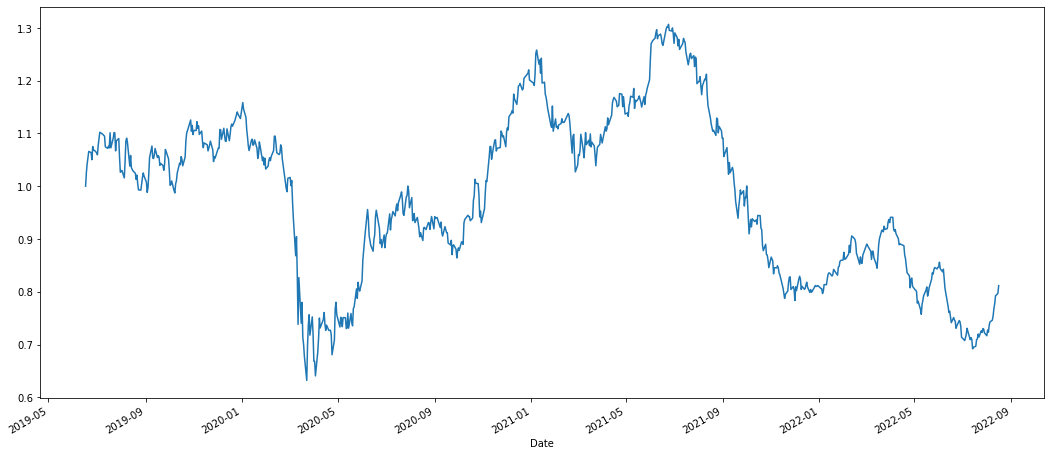

In [68]:
carteira['vl_cota'].plot()

<AxesSubplot:xlabel='Date'>

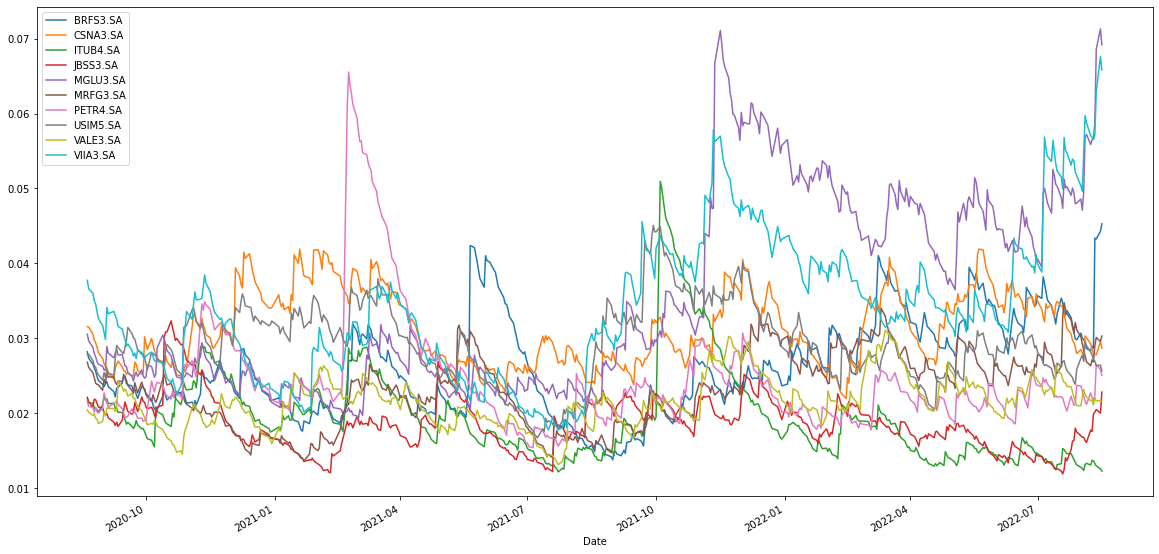

In [69]:
#Calcula a volatilidade EWMA para todos os ativos em uma janela de 252 dias
r = retr_log.ewm(alpha = 0.06, min_periods=252, adjust=False).std(252)
vol  = (r)**(1/1)
vol['2020':].plot(figsize=(20,10))

In [74]:
#Baixa os dados e calcula volatilidade para o IBOVESPA
prices = yf.download(tickers= "^BVSP", period="3y", rounding=True)['Adj Close']
retr_log_ibov = np.log(prices).diff()
retr_log_ibov.dropna(inplace=True)
ibov_vol = retr_log_ibov.ewm(alpha = 0.05, min_periods=252, adjust=False).std(252)
ibov_vol  = (ibov_vol)**(1/1)

#Calculo de correlação entre os ativosb
corr = retr_log.rolling(252).corr()
new_index = pd.MultiIndex.from_tuples(corr.index, names=['Date','Ticker'])
corr_ewma = pd.DataFrame(corr, columns = corr.columns, index=new_index)

#limpa dados NA
vol.dropna( inplace=True)
vol = vol[pesos.index[0]:pesos.index[-1]]

[*********************100%***********************]  1 of 1 completed


In [83]:
carteira['ret_IBOV'] = retr_log_ibov

<AxesSubplot:xlabel='Date'>

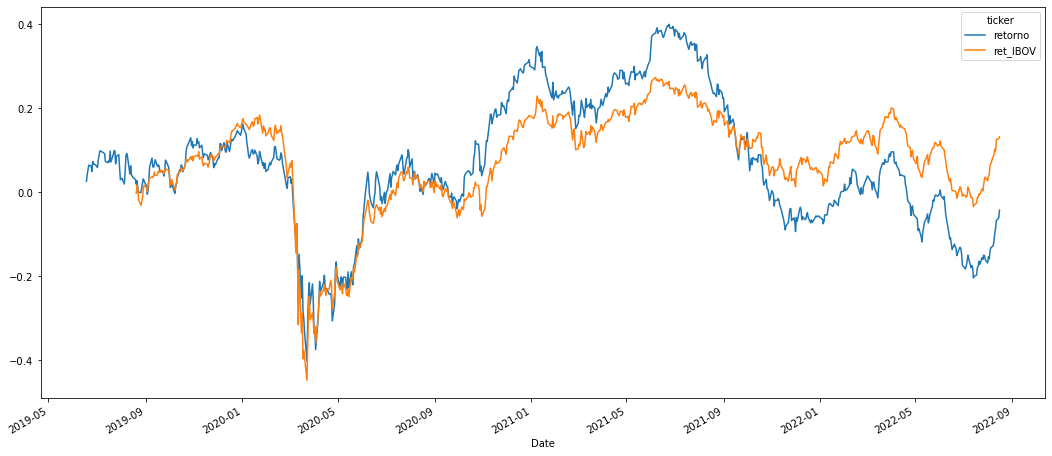

In [87]:
carteira[['retorno','ret_IBOV']].cumsum().plot()